# Chapter 7: Multi-Layer Perceptrons, Live Python Exercises (Solutions)

**ECUE 3.1.3: Neural Communication** &bull; CESI Bachelor AI (Year 2)

Reference solutions for the Chapter 7 exercises. Try the [exercise notebook](Chapter7_LiveExercises.ipynb) yourself before looking in here.

<div style="border-left: 4px solid #f59e0b; padding: 0.5em 1em; background: rgba(245,158,11,0.08);">
<b>Sanity check:</b> run the cell below. If it prints a NumPy version with no error, your environment is ready. If not, go back to <code>Chapter1_Setup.ipynb</code>.
</div>

In [1]:
import numpy as np

print("NumPy version:", np.__version__)
print("Environment OK ✔")

NumPy version: 2.5.4
Environment OK ✔


---

## Warm-Up: Same Weights, Only the Bias Changes

*Paper first, then check in code.* A neuron with **equal weights** counts its active inputs; the bias sets the threshold.

1. Fix $w = (1, 1)$. Which gate do you get with $b = -2.5$, $-1.5$, $-0.5$ and $+0.5$?
2. Fix $w = (-1, -1)$. Which gate with $b = -0.5$, $0.5$, $1.5$ and $2.5$?
3. Three inputs, $w = (1, 1, 1)$. Which gate with $b = -0.5$, $-1.5$ and $-2.5$?

Then complete the cell below to print the truth table of every neuron, and check your answers.

In [15]:
def mp_neuron(x, w, b):
    z = np.dot(w, x) + b       # weighted sum + bias (spatial summation)
    return 1 if z >= 0 else 0  # step function (all-or-nothing decision)


X_2 = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
X_3 = np.array([[a, b, c] for a in (0, 1) for b in (0, 1) for c in (0, 1)])

W_2 = np.array([[1,1], [-1,-1]])
B_2 = np.array([[-2.5, -1.5, -0.5, 0.5], [-2.5, -1.5, -0.5, 0.5]])

for w, biases in zip(W_2, B_2):
  for b in biases:
    results = [mp_neuron(x, w, b) for x in X_2]
    print(f"w = {w.tolist()}, b = {b:4.1f} -> {results}")

W_3 = np.array([1, 1, 1])
B_3 = np.array([-0.5, -1.5, -2.5])

for b in B_3:
  results = [mp_neuron(x, W_3, b) for x in X_3]
  print(f"w = {W_3.tolist()}, b = {b:4.1f} -> {results}")

w = [1, 1], b = -2.5 -> [0, 0, 0, 0]
w = [1, 1], b = -1.5 -> [0, 0, 0, 1]
w = [1, 1], b = -0.5 -> [0, 1, 1, 1]
w = [1, 1], b =  0.5 -> [1, 1, 1, 1]
w = [-1, -1], b = -2.5 -> [0, 0, 0, 0]
w = [-1, -1], b = -1.5 -> [0, 0, 0, 0]
w = [-1, -1], b = -0.5 -> [0, 0, 0, 0]
w = [-1, -1], b =  0.5 -> [1, 0, 0, 0]
w = [1, 1, 1], b = -0.5 -> [0, 1, 1, 1, 1, 1, 1, 1]
w = [1, 1, 1], b = -1.5 -> [0, 0, 0, 1, 0, 1, 1, 1]
w = [1, 1, 1], b = -2.5 -> [0, 0, 0, 0, 0, 0, 0, 1]


### Solution

| $w$ | $b$ | Gate |
|:---:|:---:|:---:|
| $(1, 1)$ | $-2.5$ | always 0 |
| $(1, 1)$ | $-1.5$ | **AND** |
| $(1, 1)$ | $-0.5$ | **OR** |
| $(1, 1)$ | $+0.5$ | always 1 |
| $(-1, -1)$ | $-0.5$ | always 0 |
| $(-1, -1)$ | $0.5$ | **NOR** |
| $(-1, -1)$ | $1.5$ | **NAND** |
| $(-1, -1)$ | $2.5$ | always 1 |
| $(1, 1, 1)$ | $-0.5$ | **OR** of 3 inputs |
| $(1, 1, 1)$ | $-1.5$ | **MAJORITY** |
| $(1, 1, 1)$ | $-2.5$ | **AND** of 3 inputs |

With equal weights, the neuron **counts** its active inputs, and the bias says **how many votes** it takes to fire: one vote is OR, two out of three is MAJORITY, all of them is AND. With inhibitory weights, the bias says how many active inputs it takes to **silence** it: one is NOR, two is NAND. That is the threshold of the biological neuron. Keep it in mind for part B: a **layer** can hold several of these neurons at once, reading the same inputs.

---

## Part A: Activations and the Collapse

### Step 1: four activation functions

`step`, `sigmoid`, `tanh` and `relu`, written so that they work on a whole NumPy array at once, and plotted for $z$ between $-5$ and $5$. **Predict**: which ones are smooth?

| | Step | Sigmoid | Tanh | ReLU |
|:---|:---:|:---:|:---:|:---:|
| $\varphi(z)$ | $1$ if $z \ge 0$, else $0$ | $\dfrac{1}{1 + e^{-z}}$ | $\tanh z$ | $\max(0, z)$ |

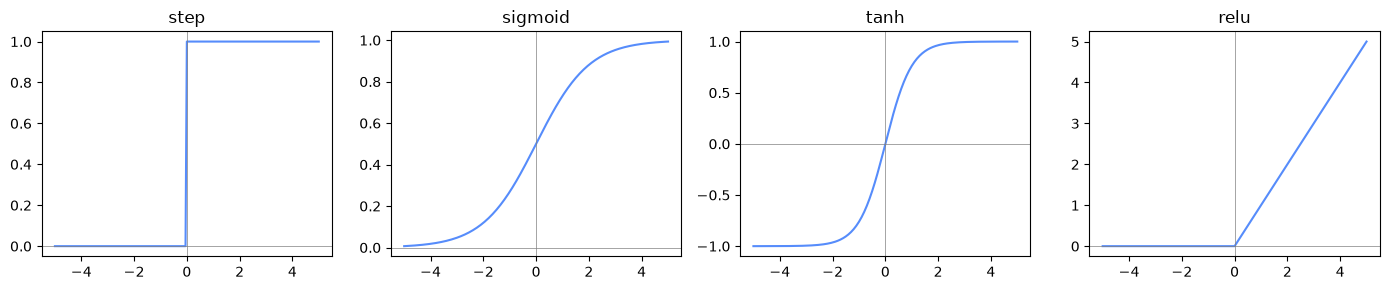

In [21]:
import matplotlib.pyplot as plt


def step(z):
    return (z >= 0).astype(int)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def tanh(z):
    return np.tanh(z)


def relu(z):
    return np.maximum(0, z)


z = np.linspace(-5, 5, 201)
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, f in zip(axes, [step, sigmoid, tanh, relu]):
    ax.plot(z, f(z))
    ax.axhline(0, color="grey", lw=0.5)
    ax.axvline(0, color="grey", lw=0.5)
    ax.set_title(f.__name__)
plt.tight_layout()
plt.show()

### Your turn: activations by hand

*Paper first.* Fill in the table, then complete the cell below to check it.

| $z$ | $-2$ | $-0.5$ | $0$ | $0.5$ | $2$ |
|:---|:---:|:---:|:---:|:---:|:---:|
| step | | | | | |
| sigmoid | | | | | |
| tanh | | | | | |
| ReLU | | | | | |

*Help*: $e^{-2} \approx 0.14$, $e^{-0.5} \approx 0.61$, $e^{0.5} \approx 1.65$, $e^{2} \approx 7.39$.

Then: which activation looks most like the **firing-rate curve** of a real neuron (silent, then graded, then saturated)? Which one can output a **negative** value? Which one never saturates?

In [23]:
z_values = np.array([-2, -0.5, 0, 0.5, 2])
for f in [step, sigmoid, tanh, relu]:
    print(f"{f.__name__:8s}", np.round(f(z_values), 2))

np.apply_along_axis(step, 0, z_values)

step     [0 0 1 1 1]
sigmoid  [0.12 0.38 0.5  0.62 0.88]
tanh     [-0.96 -0.46  0.    0.46  0.96]
relu     [0.  0.  0.  0.5 2. ]


array([0, 0, 1, 1, 1])

### Solution

| $z$ | $-2$ | $-0.5$ | $0$ | $0.5$ | $2$ |
|:---|:---:|:---:|:---:|:---:|:---:|
| step | 0 | 0 | 1 | 1 | 1 |
| sigmoid | 0.12 | 0.38 | 0.5 | 0.62 | 0.88 |
| tanh | -0.96 | -0.46 | 0 | 0.46 | 0.96 |
| ReLU | 0 | 0 | 0 | 0.5 | 2 |

- The **sigmoid** is the closest to the firing-rate curve: near 0 for a weak input, graded in the middle, saturating near 1. *Almost right* now has a value: 0.62 is closer to 1 than 0.38.
- **tanh** is the only one with **negative** outputs: the same S shape, centred on 0.
- **ReLU** never saturates: it grows without limit for positive $z$. A real neuron cannot (the refractory period caps its rate), but it makes ReLU cheap and easy to train.

### Step 2: two linear layers

Two layers **without** activation: $h = W_1 x + b_1$, then $y = W_2 h + b_2$. The cell below draws random weights: `W1` has shape `(3, 2)` (3 hidden neurons, 2 inputs), `W2` has shape `(1, 3)`.

`deep` is the output of the two layers for each of the 5 inputs in `X5`. `flat` is the output of the single layer $W' = W_2 W_1$, $b' = W_2 b_1 + b_2$. `np.allclose` compares them, up to rounding errors. (`@` is the matrix product in NumPy: `W1 @ x` computes all the weighted sums of the layer at once.)

**Predict before running**: True or False?

In [26]:
rng = np.random.default_rng(0)
W1, b1 = rng.normal(size=(3, 2)), rng.normal(size=3)
W2, b2 = rng.normal(size=(1, 3)), rng.normal(size=1)
X5 = rng.normal(size=(5, 2))

deep = [W2 @ (W1 @ x + b1) + b2 for x in X5]

Wp, bp = W2 @ W1, W2 @ b1 + b2
flat = [Wp @ x + bp for x in X5]

print("two layers == one layer?", np.allclose(deep, flat))

two layers == one layer? True


### Step 3: add a ReLU between the layers

The same two layers, with a **ReLU** on the hidden layer: $y = W_2\,\text{relu}(W_1 x + b_1) + b_2$. **Predict before running**: still equal to `flat`?

In [27]:
deep_relu = [W2 @ relu(W1 @ x + b1) + b2 for x in X5]

print("with ReLU, still one layer?", np.allclose(deep_relu, flat))

with ReLU, still one layer? False


### Solution

Without activation, the two layers and the single layer $W', b'$ give exactly the same outputs: stacking linear layers is useless. With a ReLU in between, the outputs differ: some hidden neurons are cut to zero for some inputs and not for others, and no single matrix can do that. The **non-linearity** is what makes a second layer worth having.

---

## Part B: A Feedforward Network in NumPy

A **layer** is several neurons reading the same inputs: $h = \varphi(W x + b)$, where row $j$ of $W$ holds the weights of neuron $j$.

### Step 1: one layer, then a whole network

- `layer(x, W, b, phi)` returns $\varphi(W x + b)$: the neuron of Chapter 3, for a whole layer at once.
- `forward(x, layers)`, where `layers` is a list of `(W, b, phi)`, applies them one after the other: the output of each layer is the input of the next. That's **communication** between layers.

In [28]:
def layer(x, W, b, phi):
    return phi(W @ x + b)


def forward(x, layers):
    for W, b, phi in layers:
        x = layer(x, W, b, phi)    # output of this layer -> input of the next
    return x

### Step 2: XOR, with matrices

The XOR network of Chapter 6, as two layers: the hidden layer holds OR and NAND (one per row), the output layer is AND. **Predict**: what does `forward` return on the 4 rows?

In [29]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

xor_net = [
    (np.array([[1, 1], [-1, -1]]), np.array([-0.5, 1.5]), step),   # OR and NAND
    (np.array([[1, 1]]),           np.array([-1.5]),      step),   # AND
]

print("XOR:", [int(forward(x, xor_net)[0]) for x in X])

XOR: [0, 1, 1, 0]


### Your turn: two more networks, with matrices

Chapter 6 built XOR as AND(OR, NAND). There are other ways.

1. **XOR, another way**: XOR is 1 when exactly one input is on, that is $(x_1 \text{ AND NOT } x_2)$ **OR** $(\text{NOT } x_1 \text{ AND } x_2)$. Both hidden gates are in the table of the 16 gates of Chapter 5, so each fits in one neuron. Find their weights, write the network `xor_net_2` as two layers, and check it with `forward`.
2. **XNOR**: in Chapter 6, it took a new hidden layer (AND, NOR). Now change **only the output layer** of `xor_net_2` so that the network computes XNOR (1 when both inputs are equal).
3. **Four gates in one layer**: write **one** layer `four_gates` (a $4 \times 2$ matrix and 4 biases) whose 4 neurons compute OR, AND, NAND and NOR at the same time. *Hint*: the warm-up.

In [31]:
hidden = (np.array([[1, -1], [-1, 1]]), np.array([-0.5, -0.5]), step)    # x1 AND NOT x2, NOT x1 AND x2

xor_net_2 = [hidden, (np.array([[1, 1]]), np.array([-0.5]), step)]       # output: OR
xnor_net = [hidden, (np.array([[-1, -1]]), np.array([0.5]), step)]       # output: NOR

print("XOR :", [int(forward(x, xor_net_2)[0]) for x in X])
print("XNOR:", [int(forward(x, xnor_net)[0]) for x in X])

four_gates = (np.array([[1, 1], [1, 1], [-1, -1], [-1, -1]]),            # same weights in pairs...
              np.array([-0.5, -1.5, 1.5, 0.5]),                          # ...only the biases differ
              step)
print()
print("x     -> [OR, AND, NAND, NOR]")
for x in X:
    print(x, "->", layer(x, *four_gates).tolist())

XOR : [0, 1, 1, 0]
XNOR: [1, 0, 0, 1]

x     -> [OR, AND, NAND, NOR]
[0 0] -> [0, 0, 1, 1]
[0 1] -> [1, 0, 1, 0]
[1 0] -> [1, 0, 1, 0]
[1 1] -> [1, 1, 0, 0]


### Solution

- **XOR, another way**: hidden neurons $w = (1, -1)$, $b = -0.5$ (fires only on $(1, 0)$) and $w = (-1, 1)$, $b = -0.5$ (fires only on $(0, 1)$), then an **OR** on top. Each hidden neuron has one **excitatory** and one **inhibitory** synapse.
- **XNOR**: same hidden layer, a **NOR** on top: 1 only when neither "exactly one" detector fires. Only the last layer changed: the hidden layer is a set of **features**, and the output layer decides what to do with them.
- **Four gates in one layer**: the rows come in pairs with the **same weights**, only the bias differs (warm-up). One matrix product computes the four gates at once: that is what "a layer is a matrix" means.

### Step 3: more than two classes

Three neurons were recorded while one of **three** stimuli was shown (0, 1 or 2). Each stimulus drives mostly one neuron. An output layer has **one neuron per class**; the class whose neuron has the highest score wins: $\hat{c} = \arg\max_c s_c$.

With the hand-made output layer below (`W_out` = identity: each output neuron reads its preferred input), the next cell computes the scores of each trial and predicts with `np.argmax`. **Predict** the winning class of each trial before running.

In [10]:
X3 = np.array([[40, 12, 10], [35, 15, 8], [10, 42, 12],
               [12, 38, 9], [9, 11, 45], [14, 10, 39]])
T3 = np.array([0, 0, 1, 1, 2, 2])

W_out = np.eye(3)
b_out = np.zeros(3)

In [11]:
predictions = [int(np.argmax(W_out @ x + b_out)) for x in X3]

print("predictions:", predictions, "targets:", T3.tolist())

predictions: [0, 0, 1, 1, 2, 2] targets: [0, 0, 1, 1, 2, 2]


### Step 4: learn the output layer, the multiclass perceptron rule

`train_multiclass` learns `W_out` and `b_out` instead of writing them by hand. It starts from zeros; for each trial, it predicts with the argmax; **only when wrong**, it moves the right class toward $x$ and the wrong winner away from it:

$$w_{\text{true}} \leftarrow w_{\text{true}} + \eta\,x \qquad w_{\text{pred}} \leftarrow w_{\text{pred}} - \eta\,x$$

(same for the biases, with $1$ instead of $x$). This is exactly how the Project 2 decoder learns.

`train_multiclass` takes **any** feature matrix `X`, one row per trial: firing rates here, but just as well spike counts in time windows (Chapter 3, step 5), or the outputs of a hidden layer (Chapter 6: learn the last layer on the hidden representation). The rule does not care where the numbers come from.

In [12]:
def train_multiclass(X, T, n_classes, eta=1.0, n_epochs=20):
    W, b = np.zeros((n_classes, X.shape[1])), np.zeros(n_classes)
    mistakes = []
    for epoch in range(n_epochs):
        errors = 0
        for x, t in zip(X, T):
            pred = int(np.argmax(W @ x + b))
            if pred != t:
                W[t] += eta * x
                b[t] += eta
                W[pred] -= eta * x
                b[pred] -= eta
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return W, b, mistakes


W_l, b_l, mistakes = train_multiclass(X3, T3, n_classes=3)
print("mistakes per epoch:", mistakes)
print("predictions:", [int(np.argmax(W_l @ x + b_l)) for x in X3], "targets:", T3.tolist())

mistakes per epoch: [2, 1, 0]
predictions: [0, 0, 1, 1, 2, 2] targets: [0, 0, 1, 1, 2, 2]


In [13]:
# A 3 x 3 confusion matrix: rows = true class, columns = prediction
pred = [int(np.argmax(W_l @ x + b_l)) for x in X3]
confusion = np.zeros((3, 3), dtype=int)
for t, p in zip(T3, pred):
    confusion[t, p] += 1
print(confusion)

[[2 0 0]
 [0 2 0]
 [0 0 2]]


### Solution

The hand-made output layer decodes the 6 trials correctly: each stimulus drives its own neuron, and the argmax picks it. The multiclass perceptron rule learns an output layer that does the same, from zero, in a few epochs. It's the perceptron of Chapter 5, applied to the two neurons involved in each mistake. With three classes, the confusion matrix is $3 \times 3$: here diagonal, every trial in its class.

### Your turn: three stimuli, from spike trains

The same decoder as step 4, on recordings closer to Project 2. Four neurons, **three** stimuli. Each of the first three neurons prefers one stimulus; the fourth fires at 20 Hz whatever the stimulus.

| Neuron | 1 | 2 | 3 | 4 |
|:---:|:---:|:---:|:---:|:---:|
| Stimulus 0 *(Hz)* | 30 | 15 | 15 | 20 |
| Stimulus 1 *(Hz)* | 15 | 30 | 15 | 20 |
| Stimulus 2 *(Hz)* | 15 | 15 | 30 | 20 |

The cell below simulates the trials (spikes in 1 ms bins, as in Chapter 3 and Chapter 5): 20 training and 10 test trials of 1 s per stimulus.

1. Standardize the rates with the **training** statistics, then train `train_multiclass` for 50 epochs. Does it converge?
2. Compute the test accuracy and the $3 \times 3$ confusion matrix.
3. Print `W` rounded to 1 decimal. Read it **row by row** (one output neuron per class): which input neuron does each class rely on? And neuron 4?
4. *Bonus*: redo it with trials of 0.2 s. What happens to the confusion matrix?

In [14]:
rng = np.random.default_rng(7)
dt = 0.001

rates = np.array([[30, 15, 15, 20],    # stimulus 0
                  [15, 30, 15, 20],    # stimulus 1
                  [15, 15, 30, 20]])   # stimulus 2


def record(r, n_trials, duration, rng):
    n_bins = int(duration / dt)
    X = np.zeros((n_trials, len(r)))
    for k in range(n_trials):
        spikes = (rng.random((len(r), n_bins)) < r[:, None] * dt).astype(int)
        X[k] = spikes.sum(axis=1) / duration    # firing rate in Hz
    return X


def dataset3(duration, rng, n_train=20, n_test=10):
    X_tr = np.vstack([record(r, n_train, duration, rng) for r in rates])
    T_tr = np.array([c for c in range(3) for _ in range(n_train)])
    X_te = np.vstack([record(r, n_test, duration, rng) for r in rates])
    T_te = np.array([c for c in range(3) for _ in range(n_test)])
    return X_tr, T_tr, X_te, T_te


X_tr, T_tr, X_te, T_te = dataset3(1.0, rng)
print("training set:", X_tr.shape, "| test set:", X_te.shape)


mu = X_tr.mean(axis=0)
sigma = X_tr.std(axis=0) + 1e-8
Z_tr, Z_te = (X_tr - mu) / sigma, (X_te - mu) / sigma

W_s, b_s, mistakes_s = train_multiclass(Z_tr, T_tr, n_classes=3, n_epochs=50)
print("mistakes per epoch:", mistakes_s)

pred_s = [int(np.argmax(W_s @ z + b_s)) for z in Z_te]
confusion = np.zeros((3, 3), dtype=int)
for t, p in zip(T_te, pred_s):
    confusion[t, p] += 1
print(f"test accuracy: {np.mean(np.array(pred_s) == T_te):.0%}")
print(confusion)
print("W (one row per class):")
print(np.round(W_s, 1))

training set: (60, 4) | test set: (30, 4)
mistakes per epoch: [2, 3, 3, 2, 0]
test accuracy: 97%
[[10  0  0]
 [ 0 10  0]
 [ 1  0  9]]
W (one row per class):
[[ 3.  -2.3 -1.1  0.4]
 [-1.7  3.9 -1.8  0.2]
 [-1.3 -1.6  2.9 -0.7]]


In [15]:
# Bonus: trials of 0.2 s
X_tr2, T_tr2, X_te2, T_te2 = dataset3(0.2, rng)
mu2, sigma2 = X_tr2.mean(axis=0), X_tr2.std(axis=0) + 1e-8
W2_s, b2_s, mistakes2 = train_multiclass((X_tr2 - mu2) / sigma2, T_tr2, n_classes=3, n_epochs=50)

pred2 = [int(np.argmax(W2_s @ z + b2_s)) for z in (X_te2 - mu2) / sigma2]
confusion2 = np.zeros((3, 3), dtype=int)
for t, p in zip(T_te2, pred2):
    confusion2[t, p] += 1
print("mistakes in the last 5 epochs:", mistakes2[-5:])
print(f"test accuracy (0.2 s): {np.mean(np.array(pred2) == T_te2):.0%}")
print(confusion2)

mistakes in the last 5 epochs: [14, 11, 12, 15, 19]
test accuracy (0.2 s): 57%
[[2 2 6]
 [0 7 3]
 [0 2 8]]


### Solution

1. With standardized rates, the training set is separated after **5 epochs** (2, 3, 3, 2, then 0 mistakes).
2. **97 %** on the 30 test trials: one trial of stimulus 2 is decoded as stimulus 0. The confusion matrix shows **which** classes get confused, something a single accuracy cannot.
3. Each row of `W` has **one large positive weight**, on the neuron that prefers its class (3.0, 3.9, 2.9 on the diagonal), and negative weights on the two others: "my neuron is high **and** the others are low". **Neuron 4**, which fires at 20 Hz whatever the stimulus, gets small weights in every row (0.4, 0.2, -0.7): the decoder learned to almost ignore it.
4. With 0.2 s trials, the rates are much noisier: the training never converges (11 to 19 mistakes per epoch at the end), and the test accuracy falls to about **57 %**, with errors spread over the whole matrix. Same trade-off as in Chapter 5: listen longer to decode better.

---

## Part C: Guided Demo, Let the Hidden Layer Learn

*Beyond the course: run the cells in order and read the outputs.*

So far, **we** picked every weight of the hidden layer. The XOR network has 9 numbers: 2 weights and 1 bias for each hidden neuron, and 2 weights and 1 bias for the output neuron. What happens if we reuse the **learning loop of the perceptron** (Chapter 5) on the whole network?

| Learning loop | Perceptron | Two-layer network, no hidden targets |
|:---|:---|:---|
| **1. Predict** | $y$ for one row | `network(x, p)`, with `p` = the 9 numbers |
| **2. Measure the error** | $t - y$, for this neuron | only at the output: `n_mistakes(p)` |
| **3. Correct** | $w_i \leftarrow w_i + \eta\,(t - y)\,x_i$: each weight, right direction | no target for $h_1, h_2$: nudge `p` at random, keep it if not worse |

### 1. Predict: the whole network as 9 numbers

| Neuron | Receives | Weights | Bias |
|:---|:---:|:---:|:---:|
| hidden 1 | $x_1, x_2$ | `p[0]`, `p[1]` | `p[2]` |
| hidden 2 | $x_1, x_2$ | `p[3]`, `p[4]` | `p[5]` |
| output | $h_1, h_2$ | `p[6]`, `p[7]` | `p[8]` |

`network(x, p)` makes the same three `mp_neuron` calls as `xor_network` in Chapter 6, but reads every weight and bias from `p`. Our hand-made network is just one particular `p`.

In [32]:
def mp_neuron(x, w, b):
    z = np.dot(w, x) + b       # weighted sum + bias (spatial summation)
    return 1 if z >= 0 else 0  # step function (all-or-nothing decision)


def network(x, p):
    h = [mp_neuron(x, p[0:2], p[2]),   # hidden neuron 1
         mp_neuron(x, p[3:5], p[5])]   # hidden neuron 2
    return mp_neuron(h, p[6:8], p[8])  # output neuron


X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
T = np.array([0, 1, 1, 0])

#                  hidden 1 (OR)    hidden 2 (NAND)   output (AND)
p_hand = np.array([1, 1, -0.5,     -1, -1, 1.5,      1, 1, -1.5])
print("hand-made p ->", [network(x, p_hand) for x in X], "target:", T.tolist())

hand-made p -> [0, 1, 1, 0] target: [0, 1, 1, 0]


### 2. Measure the error: `n_mistakes`

Without targets for the hidden neurons, the only error we can measure is the network's **final** answer: `n_mistakes(p, X, T)` counts the rows of the XOR table where the output is wrong. `0` for the hand-made `p`; `2` for `p = 0` (every sum is 0, so every neuron fires).

What this error **cannot** tell us: *which* of the 9 numbers is to blame, and *in which direction* to move it.

In [33]:
def n_mistakes(p, X, T):
    return sum(int(network(x, p) != t) for x, t in zip(X, T))


print("hand-made p ->", n_mistakes(p_hand, X, T), "mistake(s)")
print("p = 0       ->", n_mistakes(np.zeros(9), X, T), "mistake(s)")

hand-made p -> 0 mistake(s)
p = 0       -> 2 mistake(s)


### 3. Correct... blindly: one random nudge

Since the error gives no direction, we guess one: add a little random noise to **all 9 numbers** at once, measure again, and **keep** the new `p` if it makes no more mistakes (`m <= best`), otherwise throw it away. Five nudges from a random start:

In [18]:
rng = np.random.default_rng(0)
p = rng.normal(size=9)
best = n_mistakes(p, X, T)
print("start : outputs", [network(x, p) for x in X], "->", best, "mistake(s)")

for i in range(1, 6):
    q = p + 0.5 * rng.normal(size=9)   # propose: nudge all 9 numbers
    m = n_mistakes(q, X, T)            # measure
    if m <= best:                      # keep it if it is not worse
        p, best = q, m
        decision = "keep"
    else:
        decision = "reject"
    print(f"try {i} : outputs {[network(x, q) for x in X]} -> {m} mistake(s) -> {decision}")

start : outputs [1, 1, 1, 1] -> 2 mistake(s)
try 1 : outputs [1, 1, 1, 0] -> 1 mistake(s) -> keep
try 2 : outputs [1, 1, 1, 1] -> 2 mistake(s) -> reject
try 3 : outputs [1, 1, 0, 0] -> 2 mistake(s) -> reject
try 4 : outputs [1, 1, 1, 0] -> 1 mistake(s) -> keep
try 5 : outputs [1, 1, 1, 1] -> 2 mistake(s) -> reject


### Repeat: `random_search`

The same move in a loop, until 0 mistakes or `n_tries` tries. **Before running**: will blind guessing always find a solution?

In [34]:
def random_search(X, T, n_tries=10000, step=0.5, seed=0):
    rng = np.random.default_rng(seed)
    p = rng.normal(size=9)
    best = n_mistakes(p, X, T)
    for i in range(1, n_tries + 1):
        q = p + step * rng.normal(size=9)   # random nudge of all 9 numbers
        m = n_mistakes(q, X, T)
        if m <= best:                         # keep it if it is not worse
            p, best = q, m
        if best == 0:
            break
    return p, best, i


results = [random_search(X, T, seed=s) for s in range(20)]
for s, (p, best, n) in enumerate(results):
    print(f"seed {s:2d}: {best} mistake(s) after {n:5d} tries")
print("solved:", sum(best == 0 for _, best, _ in results), "/ 20")

p0 = results[0][0]
print("seed 0 hidden representation:",
      [[mp_neuron(x, p0[0:2], p0[2]), mp_neuron(x, p0[3:5], p0[5])] for x in X])

seed  0: 0 mistake(s) after    35 tries
seed  1: 0 mistake(s) after   113 tries
seed  2: 0 mistake(s) after  4442 tries
seed  3: 0 mistake(s) after  4639 tries
seed  4: 0 mistake(s) after   338 tries
seed  5: 1 mistake(s) after 10000 tries
seed  6: 0 mistake(s) after   324 tries
seed  7: 1 mistake(s) after 10000 tries
seed  8: 1 mistake(s) after 10000 tries
seed  9: 0 mistake(s) after   540 tries
seed 10: 0 mistake(s) after  5042 tries
seed 11: 1 mistake(s) after 10000 tries
seed 12: 0 mistake(s) after    56 tries
seed 13: 1 mistake(s) after 10000 tries
seed 14: 0 mistake(s) after  4745 tries
seed 15: 0 mistake(s) after    22 tries
seed 16: 1 mistake(s) after 10000 tries
seed 17: 1 mistake(s) after 10000 tries
seed 18: 0 mistake(s) after   197 tries
seed 19: 1 mistake(s) after 10000 tries
solved: 12 / 20
seed 0 hidden representation: [[1, 1], [0, 1], [0, 1], [0, 0]]


### What to notice

- 12 seeds out of 20 reach 0 mistakes, after 22 to 5,042 tries. The other 8 stay **stuck** at 1 mistake: after reaching it, not one nudge helps.
- **Why it gets stuck**: a small nudge rarely pushes a weighted sum across 0, so no step neuron flips and `n_mistakes` does not move. The error is **flat** almost everywhere, with no slope pointing to a better `p`.
- Seed 0's hidden layer is `[[1, 1], [0, 1], [0, 1], [0, 0]]`: NOR and NAND, not OR and NAND. The search found its **own** hidden features.

It learns, but **blindly**: the error says the network is wrong, never *which* weight to blame or in which direction to move it.

### Your turn: tune the blind search

The blind search got stuck for 8 seeds out of 20. Two ideas to help it:

1. **Change the size of the nudge.** Run `random_search` on the 20 seeds with `step = 0.1`, `0.5` and `2.0`. For each, count the solved seeds and the median number of tries of the solved ones (`np.median`). Is there a "best" step?
2. **Restart when stuck.** Write `random_search_restart`: the same loop, but if `patience = 500` tries go by without a **strict** improvement, start again from a new random `p`. How many seeds out of 20 are solved now?
3. What does this tell you about learning without a direction?

In [20]:
for step_size in [0.1, 0.5, 2.0]:
    runs = [random_search(X, T, step=step_size, seed=s) for s in range(20)]
    tries = [n for _, best, n in runs if best == 0]
    print(f"step = {step_size}: {len(tries):2d} / 20 solved, median tries of the solved: {np.median(tries):.0f}")


def random_search_restart(X, T, n_tries=10000, step=0.5, patience=500, seed=0):
    rng = np.random.default_rng(seed)
    p = rng.normal(size=9)
    best = n_mistakes(p, X, T)
    last_improvement = 0
    for i in range(1, n_tries + 1):
        q = p + step * rng.normal(size=9)
        m = n_mistakes(q, X, T)
        if m < best:                              # a strict improvement
            last_improvement = i
        if m <= best:
            p, best = q, m
        if best == 0:
            break
        if i - last_improvement >= patience:      # stuck: start again elsewhere
            p = rng.normal(size=9)
            best = n_mistakes(p, X, T)
            last_improvement = i
    return p, best, i


runs = [random_search_restart(X, T, seed=s) for s in range(20)]
tries = [n for _, best, n in runs if best == 0]
print(f"with restarts: {len(tries)} / 20 solved, median tries: {np.median(tries):.0f}")

step = 0.1:  8 / 20 solved, median tries of the solved: 1180


step = 0.5: 12 / 20 solved, median tries of the solved: 331


step = 2.0: 11 / 20 solved, median tries of the solved: 711


with restarts: 20 / 20 solved, median tries: 956


### Solution

| step | solved | median tries |
|:---:|:---:|:---:|
| 0.1 | 8 / 20 | 1180 |
| 0.5 | 12 / 20 | 331 |
| 2.0 | 11 / 20 | 711 |

1. A small step barely moves the weighted sums, so the error almost never changes: the search wanders on a flat plateau. A large step jumps far, but mostly to worse places, so most nudges are rejected. 0.5 does best here, but **no** step solves every seed.
2. With restarts after 500 tries without progress, **20 / 20** seeds are solved, median 956 tries. A stuck run is not repaired: it is **abandoned**, and a new random start gets another chance.
3. Without a direction, the only tools are luck and patience: try, keep what is not worse, start again when stuck. It works on 9 numbers. A real network has millions of weights, and random guessing would never finish. That is why the next slide matters: the **backward pass** gives every weight a direction.

---

## Feedforward, Backward Pass, Backpropagation

- **Biological neurons** communicate **one way**: dendrites, soma, axon, synapse.
- **Feedforward** (forward pass): input, hidden, output. The network **computes** its answer: that's what `forward` does.
- **Backward pass**: the **error** at the output is sent **back**, layer by layer, and tells each weight how much it contributed and in which direction to move.
- **Backpropagation** (Rumelhart, Hinton & Williams, 1986): the algorithm that computes the backward pass. It needs **smooth** activations, like the sigmoid of part A.

The guided demo had a forward pass, but no backward pass: it could only guess.